# 02 - Optimización e hiperparámetros (TensorFlow/Keras)

Compara SGD con Momentum, RMSprop y Adam, manteniendo el mismo conjunto de datos, arquitectura, batch size y número de épocas. Después compara tres learning rates de Adam. Usa Dev para comparar; Test sigue reservado.

## 1. Preparar entorno y datos

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
OUTPUT_DIR = Path("resultados")
OUTPUT_DIR.mkdir(exist_ok=True)
print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)

TensorFlow: 2.21.0
Semilla: 42


In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Las imágenes se mantienen en escala de grises (28 x 28); solo se escala su intensidad.
x_train = x_train.astype("float32") / 255.0
x_dev   = x_dev.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)
print("Rango de Train:", float(x_train.min()), float(x_train.max()))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)
Rango de Train: 0.0 1.0


## 2. Crear la misma arquitectura para todos los optimizadores

In [ ]:
def crear_modelo_experimento(optimizador, units=128):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(
        optimizer=optimizador,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

## 3. Comparar SGD + Momentum, RMSprop y Adam

In [ ]:
fabricas_optimizadores = {
    "SGD_momentum": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001),
}

resultados_opt = []
historias_opt = {}

for nombre, fabrica in fabricas_optimizadores.items():
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)  # misma semilla inicial en cada comparación
    modelo = crear_modelo_experimento(fabrica())  # optimizador nuevo para cada modelo
    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=5,
        batch_size=64,
        verbose=0
    )
    historias_opt[nombre] = historia
    resultados_opt.append({
        "optimizador": nombre,
        "train_accuracy": historia.history["accuracy"][-1],
        "dev_accuracy": historia.history["val_accuracy"][-1],
        "dev_loss": historia.history["val_loss"][-1]
    })

tabla_opt = pd.DataFrame(resultados_opt).sort_values("dev_loss")
display(tabla_opt)
tabla_opt.to_csv(OUTPUT_DIR / "comparacion_optimizadores.csv", index=False)

,optimizador,train_accuracy,dev_accuracy,dev_loss
1,RMSprop,0.981500,0.968750,0.105790
2,Adam,0.983146,0.966167,0.114182
0,SGD_momentum,0.967562,0.958333,0.141419


## 4. Comparar las curvas de Dev Loss

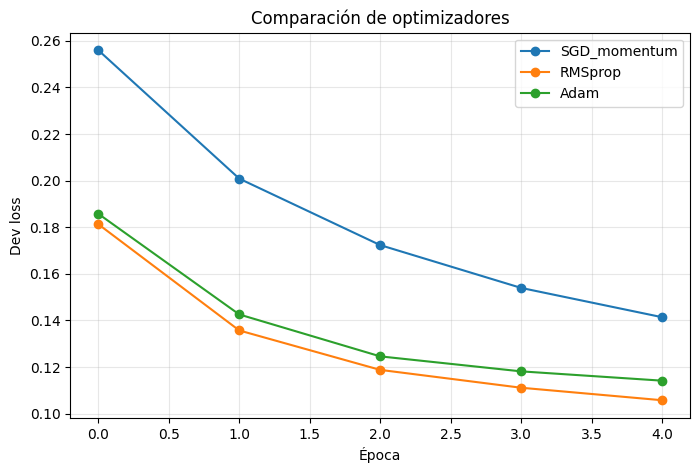

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for nombre, historia in historias_opt.items():
    ax.plot(historia.history["val_loss"], marker="o", label=nombre)
ax.set_xlabel("Época"); ax.set_ylabel("Dev loss")
ax.set_title("Comparación de optimizadores")
ax.grid(True, alpha=.3); ax.legend()
fig.savefig(OUTPUT_DIR / "comparacion_optimizadores.png", dpi=180, bbox_inches="tight")
plt.show()

**Interpretación:** elige el optimizador que bajo estas condiciones presentó una combinación más favorable de Dev loss, Dev accuracy y estabilidad. No concluyas que un optimizador es siempre mejor: la conclusión aplica a este experimento.

## 5. Explorar el learning rate de Adam

In [ ]:
learning_rates = [0.0001, 0.001, 0.01]
resultados_lr = []
historias_lr = {}

for lr in learning_rates:
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    modelo = crear_modelo_experimento(keras.optimizers.Adam(learning_rate=lr))
    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=3,
        batch_size=64,
        verbose=0
    )
    historias_lr[lr] = historia
    resultados_lr.append({
        "learning_rate": lr,
        "train_accuracy": historia.history["accuracy"][-1],
        "dev_accuracy": historia.history["val_accuracy"][-1],
        "dev_loss": historia.history["val_loss"][-1]
    })

tabla_lr = pd.DataFrame(resultados_lr).sort_values("dev_loss")
display(tabla_lr)
tabla_lr.to_csv(OUTPUT_DIR / "comparacion_learning_rate.csv", index=False)

,learning_rate,train_accuracy,dev_accuracy,dev_loss
1,0.0010,0.970187,0.963500,0.124607
2,0.0100,0.968458,0.948667,0.217702
0,0.0001,0.919771,0.923917,0.277345


## 6. Gráfica de learning rate

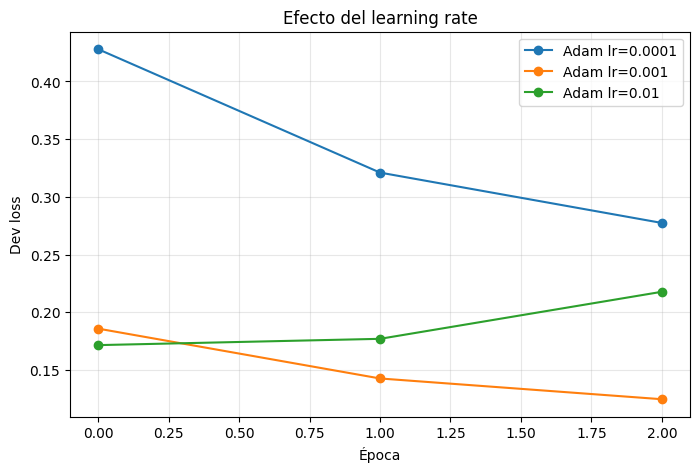

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for lr, historia in historias_lr.items():
    ax.plot(historia.history["val_loss"], marker="o", label=f"Adam lr={lr}")
ax.set_xlabel("Época"); ax.set_ylabel("Dev loss"); ax.set_title("Efecto del learning rate")
ax.grid(True, alpha=.3); ax.legend()
fig.savefig(OUTPUT_DIR / "comparacion_learning_rate.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Análisis requerido

1. ¿Qué optimizador obtuvo menor Dev loss y cuál Dev accuracy mayor?
2. ¿La evolución fue estable o fluctuó?
3. ¿Qué pasó al usar learning rate 0.0001, 0.001 y 0.01?
4. Explica que un paso alto puede causar inestabilidad y uno muy bajo puede aprender lentamente.
5. No uses el conjunto Test para seleccionar configuraciones.

**Importante:** pega en el informe las tablas que genere este notebook y explica lo que realmente observaste; no inventes resultados.